In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view

In [2]:

from sklearn.metrics import mean_absolute_error


In [3]:
ticker = "GLD"
data = yf.download(ticker, start="2015-01-01", end="2025-01-01")

price = data["Close"].dropna()

C:\Users\ANI\AppData\Local\Temp\ipykernel_42540\3188468989.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed


In [4]:
transformed_price =np.log(price).dropna().values

In [5]:
print(transformed_price.shape)
print(transformed_price.ndim)


(2516, 1)
2


In [6]:
L=2
K=4
P=0.2

In [7]:
transformed_price.shape

(2516, 1)

In [8]:
def horizon(x, L, N):
    x = np.asarray(x).ravel()
    windows = sliding_window_view(x, L)
    X = windows[:len(x) - L - N + 1]
    y = x[L + N - 1 : L + N - 1 + len(X)]
    
    return X, y

In [9]:
gmae = []

for N in range(1, K + 1):
    X, y = horizon(transformed_price, L, N)
    split = int((1 - P) * len(X))
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    model = KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    errors = np.abs(y_test - y_pred)

    gmae_N = np.exp(np.mean(np.log(errors + 1e-12)))
    gmae.append(gmae_N)

    print(f"N = {N}, GMAE = {gmae_N:.6e}")


N = 1, GMAE = 2.379096e-02
N = 2, GMAE = 3.120112e-02
N = 3, GMAE = 3.609231e-02
N = 4, GMAE = 4.160944e-02


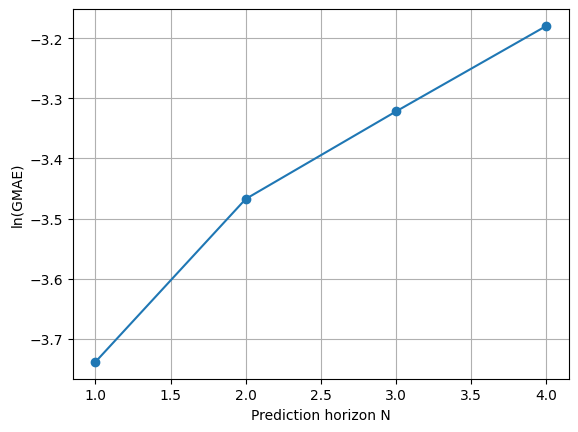

In [10]:
import numpy as np
import matplotlib.pyplot as plt

N_vals = np.arange(1, K+1)
log_gmae = np.log(gmae)

plt.plot(N_vals, log_gmae, 'o-')
plt.xlabel("Prediction horizon N")
plt.ylabel("ln(GMAE)")
plt.grid(True)
plt.show()


In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression
n = np.arange(1, K+1).reshape(-1, 1)                   
reg = LinearRegression().fit(n, np.log(gmae) )
LLE = reg.coef_[0]

print("largest Lyapunov exponent λ =", LLE)

largest Lyapunov exponent λ = 0.18226895943702312
